In [14]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report,accuracy_score,confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sd

## ***Load the Employee Data***

In [15]:
employees_absenteesim=pd.read_csv('C:/Users/arpit/OneDrive/Desktop/Employee Attrition Analysis/employees_absenteeism_2000.csv')
employees_performance=pd.read_csv('C:/Users/arpit/OneDrive/Desktop/Employee Attrition Analysis/employees_performance_2000.csv')
employees_compensation=pd.read_csv('C:/Users/arpit/OneDrive/Desktop/Employee Attrition Analysis/employees_compensation_2000.csv')
employees_demographics=pd.read_csv('C:/Users/arpit/OneDrive/Desktop/Employee Attrition Analysis/employees_demographics_2000.csv')



### *Merge all four tables on the common **'EmployeeID'**  key*

In [16]:
Attrition_Table=employees_absenteesim.merge(employees_performance,on='EmployeeID').merge(employees_compensation,on='EmployeeID').merge(employees_demographics,on="EmployeeID")

### *Convert the target variable 'Attrition' from text to binary **(Yes=1, No=0)***

In [17]:
Attrition_Table['Attrition']=Attrition_Table['Attrition'].map({'Yes':1,'No':0})

### *Drop **'EmployeeID'** beacuse it is an identifier, not a predictive variable*

In [18]:
Attrition_Table=Attrition_Table.drop('EmployeeID',axis=1)

### *One-Hot Encode categorical variables (e.g.,turning **'Department'** into separate binary columns)*

In [19]:
categorical_columns=['Department','Contract_Type','Mobility_Budget_Opt_In']
Attrition_Table_encoded=pd.get_dummies(Attrition_Table,columns=categorical_columns,drop_first=True)

### *Separate the Variables **(X)** from the target **(Y)***

In [20]:
X=Attrition_Table_encoded.drop('Attrition',axis=1)
y=Attrition_Table_encoded['Attrition']

### *Split data into 80% training and 20% testing*
### ***stratify = y ensure the same ratio of Attrition in both sets***

### *Initialize the Random Forest Model*
### ***class_weight = 'balanced' helps counteract the fact that fewer people leave than stay***

### *Make predictions on the unseen test data*

In [21]:
X_train, X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=420,stratify=y)
Attrition_model=RandomForestClassifier(n_estimators=1000,random_state=420,class_weight='balanced')
Attrition_model.fit(X_train,y_train) 
y_predicted=Attrition_model.predict(X_test)

In [22]:
print('___ Model Performance ___')
print(f'Accuracy: {accuracy_score(y_test,y_predicted):.2f}')
print('Classification Report:')
print(classification_report(y_test,y_predicted))

___ Model Performance ___
Accuracy: 0.84
Classification Report:
              precision    recall  f1-score   support

           0       0.84      1.00      0.92       338
           1       0.00      0.00      0.00        62

    accuracy                           0.84       400
   macro avg       0.42      0.50      0.46       400
weighted avg       0.71      0.84      0.77       400



C:\Users\arpit\AppData\Roaming\Python\Python39\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\arpit\AppData\Roaming\Python\Python39\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\arpit\AppData\Roaming\Python\Python39\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is",

### *Extract the importance of each variable*

In [23]:
Attrition__feature_importances=pd.DataFrame({'Feature':X.columns,'Importance':Attrition_model.feature_importances_}).sort_values(by='Importance',ascending=False)

In [24]:
print('\n---Top Attrition Drivers---')
print(Attrition__feature_importances.head(10))


---Top Attrition Drivers---
                         Feature  Importance
7                Base_Salary_EUR    0.103798
9               Annual_Bonus_EUR    0.100636
13           Commute_Distance_km    0.100470
3   Avg_Overtime_Hours_Per_Month    0.096594
8         Salary_Growth_Rate_Pct    0.089877
6       Training_Hours_Completed    0.087101
5     Years_Since_Last_Promotion    0.087039
10                           Age    0.079164
2            Vacation_Days_Taken    0.072270
0    Short_Term_Sick_Leave_Count    0.041053


### *Plot the Variable Importances*

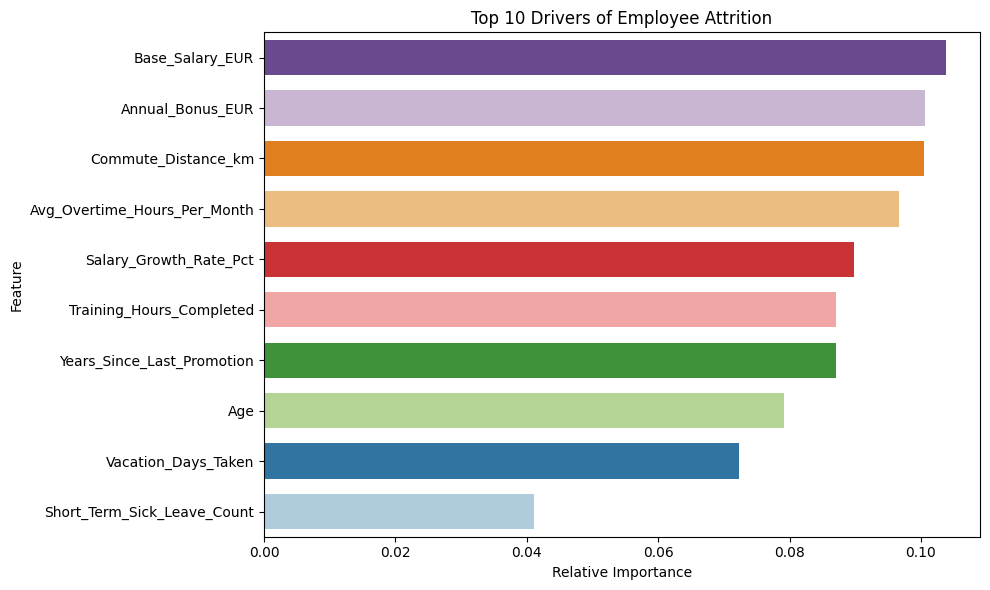

In [40]:
plt.figure(figsize=(10, 6))
sd.barplot(x='Importance', y='Feature', data=Attrition__feature_importances.head(10),hue='Importance',width=0.7,palette='Paired',legend=False)
plt.title('Top 10 Drivers of Employee Attrition')
plt.xlabel('Relative Importance')
plt.tight_layout();

In [31]:
Attrition__feature_importances.to_csv('C:/Users/arpit/OneDrive/Desktop/Employee Attrition Analysis/Attrition Predictive Model.csv',index=False)